# 06 Monte Carlo Weight Uncertainty

This notebook uses only `data/processed/dfsi_verified_baseline.csv`, restricted to the 709 complete valid district records. The analytical baseline is the correctly reconstructed DFSI, not the published DFSI score.

## Setup

In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 180)

EXPECTED_BASELINE = Path("data") / "processed" / "dfsi_verified_baseline.csv"


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / EXPECTED_BASELINE).exists():
            return candidate
    raise FileNotFoundError("Could not find data/processed/dfsi_verified_baseline.csv from the current working directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
BASELINE_PATH = PROJECT_ROOT / EXPECTED_BASELINE
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
N_DISTRICTS_EXPECTED = 709
TOP10_N = 71
BASELINE_WEIGHTS = np.array([1.0, 1.0, 2.0, 1.0, 1.0, 1.0], dtype="float64")
BASELINE_PROPORTIONS = BASELINE_WEIGHTS / BASELINE_WEIGHTS.sum()
COMPONENTS = ["events", "duration", "fatalities", "injured", "flooded_area", "population"]
UNWEIGHTED_TERM_COLUMNS = ["u_events", "u_duration", "u_fatalities", "u_injured", "u_flooded_area", "u_population"]
SCENARIOS = [
    {"scenario": "narrow", "concentration": 100.0, "simulations": 10_000},
    {"scenario": "moderate", "concentration": 30.0, "simulations": 10_000},
    {"scenario": "wide", "concentration": 10.0, "simulations": 10_000},
]

print(f"Project root: {PROJECT_ROOT}")
print(f"Input baseline: {BASELINE_PATH.relative_to(PROJECT_ROOT)}")

Project root: /Users/abhijithshaji/Documents/india-flood-index-robustness
Input baseline: data/processed/dfsi_verified_baseline.csv


## 1. Construct Unweighted Component Terms

The published baseline weights are `[1, 1, 2, 1, 1, 1]`, summing to 7. Applying them to these unweighted terms must reproduce the verified reconstructed DFSI and ranking.

In [2]:
baseline_source = pd.read_csv(BASELINE_PATH)
print(f"Verified baseline rows: {len(baseline_source):,}")

required_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
    "reconstructed_dfsi",
    "reconstructed_rank",
    "completeness_status",
    "join_status",
]
missing_columns = [column for column in required_columns if column not in baseline_source.columns]
if missing_columns:
    raise KeyError(f"Missing required baseline columns: {missing_columns}")

analysis = baseline_source.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy()
component_input_columns = [
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
]
for column in component_input_columns:
    analysis[column] = pd.to_numeric(analysis[column], errors="coerce").astype("float64")
analysis["reconstructed_dfsi"] = pd.to_numeric(analysis["reconstructed_dfsi"], errors="coerce").astype("float64")
analysis = analysis.dropna(subset=component_input_columns + ["reconstructed_dfsi"]).copy()
analysis = analysis.sort_values(["reconstructed_rank", "State_Name", "district_name"]).reset_index(drop=True)

assert len(analysis) == N_DISTRICTS_EXPECTED, f"Expected exactly {N_DISTRICTS_EXPECTED} districts, got {len(analysis)}"
for column in component_input_columns:
    assert analysis[column].ge(0).all(), f"Negative component in {column}"
assert analysis["population"].gt(0).all(), "Population must be positive"

analysis["district_id"] = np.arange(len(analysis), dtype="int64")
analysis["u_events"] = np.log10(1.0 + analysis["flood_event_count"])
analysis["u_duration"] = np.log10(1.0 + analysis["mean_flood_duration"])
analysis["u_fatalities"] = np.log10(1.0 + analysis["fatalities"])
analysis["u_injured"] = np.log10(1.0 + analysis["injured"])
analysis["u_flooded_area"] = np.log10(1.0 + analysis["corrected_percent_flooded_area"])
analysis["u_population"] = np.log10(analysis["population"])

terms = analysis[UNWEIGHTED_TERM_COLUMNS].to_numpy(dtype="float64")
baseline_weighted_dfsi = terms @ BASELINE_WEIGHTS
analysis["baseline_dfsi"] = baseline_weighted_dfsi
analysis["baseline_rank"] = pd.Series(baseline_weighted_dfsi).rank(ascending=False, method="min").astype("int64").to_numpy()
analysis["baseline_top10"] = analysis["baseline_rank"].le(TOP10_N)
analysis["baseline_top25"] = analysis["baseline_rank"].le(25)
analysis["baseline_top50"] = analysis["baseline_rank"].le(50)
analysis["baseline_top100"] = analysis["baseline_rank"].le(100)

max_score_diff = np.max(np.abs(analysis["baseline_dfsi"].to_numpy() - analysis["reconstructed_dfsi"].to_numpy()))
rank_diff_max = np.max(np.abs(analysis["baseline_rank"].to_numpy() - pd.to_numeric(analysis["reconstructed_rank"], errors="coerce").to_numpy()))
assert max_score_diff <= 1e-10, f"Baseline weights do not reproduce verified reconstructed DFSI: {max_score_diff}"
assert rank_diff_max <= 0, f"Baseline ranks do not reproduce verified reconstructed ranks: {rank_diff_max}"
assert analysis.loc[analysis["baseline_rank"].eq(1), "baseline_dfsi"].eq(analysis["baseline_dfsi"].max()).all(), "Baseline rank 1 is not maximum baseline DFSI"

print(f"Complete valid records: {len(analysis):,}")
print(f"Max score difference from verified reconstructed DFSI: {max_score_diff}")
display(analysis[["State_Name", "district_name", *UNWEIGHTED_TERM_COLUMNS, "baseline_dfsi", "baseline_rank"]].head())

Verified baseline rows: 720
Complete valid records: 709
Max score difference from verified reconstructed DFSI: 5.329070518200751e-15


,State_Name,district_name,u_events,u_duration,u_fatalities,u_injured,u_flooded_area,u_population,baseline_dfsi,baseline_rank
0,MAHARASHTRA,Mumbai,2.238046,0.602060,3.007321,2.641474,0.000434,6.452029,17.948685,1
1,BIHAR,Patna,1.857332,1.230449,2.582063,1.491362,1.297117,6.836890,17.877277,2
2,MAHARASHTRA,Thane,1.991226,0.602060,2.622214,2.311754,0.352882,6.997831,17.500181,3
3,MAHARASHTRA,Nagpur,2.250420,0.602060,2.838849,1.897627,0.145588,6.719528,17.292922,4
4,WEST BENGAL,Murshidabad,1.653213,1.380211,2.639486,1.000000,1.057078,6.921722,17.291197,5


## Monte Carlo Helpers

In [3]:
def descending_ranks(score_matrix):
    """Return 1-based descending ranks for each simulation column."""
    order = np.argsort(-score_matrix, axis=0, kind="mergesort")
    ranks = np.empty_like(order, dtype=np.int16)
    sim_index = np.arange(score_matrix.shape[1])
    ranks[order, sim_index] = np.arange(1, score_matrix.shape[0] + 1, dtype=np.int16)[:, None]
    return ranks


def rank_corr_with_baseline(ranks, baseline_ranks):
    baseline_centered = baseline_ranks.astype("float64") - baseline_ranks.mean()
    ranks_centered = ranks.astype("float64") - ranks.mean(axis=0)
    numerator = (baseline_centered[:, None] * ranks_centered).sum(axis=0)
    denominator = np.sqrt((baseline_centered ** 2).sum() * (ranks_centered ** 2).sum(axis=0))
    return numerator / denominator


def summarize_rank_distribution(ranks):
    return {
        "mean_simulated_rank": ranks.mean(axis=1),
        "median_simulated_rank": np.median(ranks, axis=1),
        "minimum_simulated_rank": ranks.min(axis=1),
        "maximum_simulated_rank": ranks.max(axis=1),
        "rank_p05": np.percentile(ranks, 5, axis=1),
        "rank_p25": np.percentile(ranks, 25, axis=1),
        "rank_p75": np.percentile(ranks, 75, axis=1),
        "rank_p95": np.percentile(ranks, 95, axis=1),
        "rank_standard_deviation": ranks.std(axis=1, ddof=1),
        "top10_probability": (ranks <= TOP10_N).mean(axis=1),
        "top25_probability": (ranks <= 25).mean(axis=1),
        "top50_probability": (ranks <= 50).mean(axis=1),
        "top100_probability": (ranks <= 100).mean(axis=1),
    }


baseline_ranks = analysis["baseline_rank"].to_numpy(dtype="float64")
baseline_top10_mask = analysis["baseline_top10"].to_numpy(dtype=bool)
scenario_alphas = {scenario["scenario"]: BASELINE_PROPORTIONS * scenario["concentration"] for scenario in SCENARIOS}

## 2–3. Monte Carlo Weight Sampling and Ranking Simulation

Weights are sampled from Dirichlet distributions centred on the published baseline proportions and then rescaled so each sampled vector sums to 7. No negative weights are allowed.

In [4]:
rng = np.random.default_rng(RANDOM_SEED)
scenario_district_frames = []
scenario_summary_records = []
weight_summary_records = []
weights_frames = []
scenario_rank_cache = {}

for scenario_spec in SCENARIOS:
    scenario = scenario_spec["scenario"]
    concentration = scenario_spec["concentration"]
    simulations = scenario_spec["simulations"]
    alpha = scenario_alphas[scenario]

    proportions = rng.dirichlet(alpha, size=simulations)
    weights = proportions * BASELINE_WEIGHTS.sum()

    assert np.all(weights > 0), f"Non-positive sampled weights in {scenario}"
    assert np.allclose(weights.sum(axis=1), BASELINE_WEIGHTS.sum(), atol=1e-10), f"Sampled weights do not sum to 7 in {scenario}"

    scores = terms @ weights.T
    assert np.isfinite(scores).all(), f"Non-finite scores in {scenario}"
    ranks = descending_ranks(scores)
    assert np.isfinite(ranks).all(), f"Non-finite ranks in {scenario}"
    assert ranks.shape == (N_DISTRICTS_EXPECTED, simulations), f"Unexpected rank matrix shape for {scenario}: {ranks.shape}"
    assert np.all((ranks <= TOP10_N).sum(axis=0) == TOP10_N), f"Top 10% count is not exactly {TOP10_N} in every {scenario} simulation"

    scenario_rank_cache[scenario] = ranks
    rank_spearman = rank_corr_with_baseline(ranks, baseline_ranks)
    top10_counts = (ranks <= TOP10_N).sum(axis=0)
    top10_overlap = ((ranks <= TOP10_N) & baseline_top10_mask[:, None]).sum(axis=0)
    entering_leaving = TOP10_N - top10_overlap

    district_stats = summarize_rank_distribution(ranks)
    district_frame = analysis[[
        "district_id",
        "State_Name",
        "district_name",
        "available_state_identifier",
        "available_state_review_key",
        "available_district_identifier",
        "available_district_review_key",
        "available_district_lgd_codes",
        "available_district_lgd_code_count",
        "baseline_dfsi",
        "baseline_rank",
        "baseline_top10",
        "baseline_top25",
        "baseline_top50",
        "baseline_top100",
    ]].copy()
    district_frame.insert(0, "scenario", scenario)
    district_frame["concentration"] = concentration
    district_frame["simulations"] = simulations
    for column, values in district_stats.items():
        district_frame[column] = values
    district_frame["rank_p05_to_p95_interval"] = district_frame["rank_p95"] - district_frame["rank_p05"]
    scenario_district_frames.append(district_frame)

    scenario_summary_records.append({
        "scenario": scenario,
        "concentration": concentration,
        "simulations": simulations,
        "district_count": N_DISTRICTS_EXPECTED,
        "median_spearman_correlation_with_baseline_rank": np.median(rank_spearman),
        "spearman_correlation_p05": np.percentile(rank_spearman, 5),
        "spearman_correlation_p95": np.percentile(rank_spearman, 95),
        "mean_top10_overlap_with_baseline": top10_overlap.mean(),
        "minimum_top10_overlap_with_baseline": top10_overlap.min(),
        "maximum_top10_overlap_with_baseline": top10_overlap.max(),
        "median_districts_entering_leaving_baseline_top10": np.median(entering_leaving),
        "top10_n": TOP10_N,
        "robust_high_priority_districts": np.nan,  # filled after moderate categorisation
        "weight_sensitive_priority_districts": np.nan,
        "sampled_weight_sum_min": weights.sum(axis=1).min(),
        "sampled_weight_sum_max": weights.sum(axis=1).max(),
    })

    for component_index, component in enumerate(COMPONENTS):
        component_weights = weights[:, component_index]
        weight_summary_records.append({
            "scenario": scenario,
            "concentration": concentration,
            "component": component,
            "baseline_weight": BASELINE_WEIGHTS[component_index],
            "baseline_proportion": BASELINE_PROPORTIONS[component_index],
            "mean_weight": component_weights.mean(),
            "standard_deviation": component_weights.std(ddof=1),
            "weight_p05": np.percentile(component_weights, 5),
            "median_weight": np.median(component_weights),
            "weight_p95": np.percentile(component_weights, 95),
            "minimum_weight": component_weights.min(),
            "maximum_weight": component_weights.max(),
            "mean_close_to_baseline_weight": np.isclose(component_weights.mean(), BASELINE_WEIGHTS[component_index], rtol=0.03, atol=0.03),
        })

    weights_df = pd.DataFrame(weights, columns=[f"weight_{component}" for component in COMPONENTS])
    weights_df.insert(0, "simulation", np.arange(1, simulations + 1, dtype="int64"))
    weights_df.insert(0, "scenario", scenario)
    weights_df["weight_sum"] = weights.sum(axis=1)
    weights_frames.append(weights_df)

mc_district_uncertainty = pd.concat(scenario_district_frames, ignore_index=True)
mc_scenario_summary = pd.DataFrame(scenario_summary_records)
mc_weight_summary = pd.DataFrame(weight_summary_records)
mc_sampled_weights = pd.concat(weights_frames, ignore_index=True)

for column in ["top10_probability", "top25_probability", "top50_probability", "top100_probability"]:
    assert mc_district_uncertainty[column].between(0, 1).all(), f"Probability outside [0, 1] in {column}"

# Reproducibility check: resample with the same seed and compare sampled weights.
rng_check = np.random.default_rng(RANDOM_SEED)
check_frames = []
for scenario_spec in SCENARIOS:
    scenario = scenario_spec["scenario"]
    alpha = scenario_alphas[scenario]
    check_weights = rng_check.dirichlet(alpha, size=scenario_spec["simulations"]) * BASELINE_WEIGHTS.sum()
    check_df = pd.DataFrame(check_weights, columns=[f"weight_{component}" for component in COMPONENTS])
    check_df.insert(0, "simulation", np.arange(1, scenario_spec["simulations"] + 1, dtype="int64"))
    check_df.insert(0, "scenario", scenario)
    check_df["weight_sum"] = check_weights.sum(axis=1)
    check_frames.append(check_df)
mc_sampled_weights_check = pd.concat(check_frames, ignore_index=True)
assert np.allclose(
    mc_sampled_weights[[f"weight_{component}" for component in COMPONENTS]].to_numpy(),
    mc_sampled_weights_check[[f"weight_{component}" for component in COMPONENTS]].to_numpy(),
), "Random seed reproducibility check failed"

print("Monte Carlo simulations complete.")
display(mc_scenario_summary)
display(mc_weight_summary.head(12))

Monte Carlo simulations complete.


,scenario,concentration,simulations,district_count,median_spearman_correlation_with_baseline_rank,spearman_correlation_p05,spearman_correlation_p95,mean_top10_overlap_with_baseline,minimum_top10_overlap_with_baseline,maximum_top10_overlap_with_baseline,median_districts_entering_leaving_baseline_top10,top10_n,robust_high_priority_districts,weight_sensitive_priority_districts,sampled_weight_sum_min,sampled_weight_sum_max
0,narrow,100.0,10000,709,0.995934,0.988190,0.998923,63.6137,46,71,7.0,71,NaN,NaN,7.0,7.0
1,moderate,30.0,10000,709,0.987768,0.963424,0.996597,58.9362,37,70,11.0,71,NaN,NaN,7.0,7.0
2,wide,10.0,10000,709,0.968132,0.900572,0.990891,52.8193,27,69,17.0,71,NaN,NaN,7.0,7.0


,scenario,concentration,component,baseline_weight,baseline_proportion,mean_weight,standard_deviation,weight_p05,median_weight,weight_p95,minimum_weight,maximum_weight,mean_close_to_baseline_weight
0,narrow,100.0,events,1.0,0.142857,1.001080,0.242519,0.638742,0.986725,1.433919,0.290848,1.990693,True
1,narrow,100.0,duration,1.0,0.142857,1.003918,0.247322,0.624909,0.984518,1.442615,0.300172,2.240727,True
2,narrow,100.0,fatalities,2.0,0.285714,1.995943,0.315821,1.493523,1.988175,2.530079,0.910290,3.432466,True
3,narrow,100.0,injured,1.0,0.142857,0.997483,0.246294,0.617769,0.978188,1.425553,0.341103,2.201420,True
4,narrow,100.0,flooded_area,1.0,0.142857,1.000693,0.242577,0.631746,0.983703,1.422252,0.341114,2.093628,True
5,narrow,100.0,population,1.0,0.142857,1.000883,0.245829,0.625040,0.983506,1.433964,0.302967,2.084623,True
6,moderate,30.0,events,1.0,0.142857,0.998603,0.441221,0.374421,0.944655,1.798594,0.068867,3.321299,True
7,moderate,30.0,duration,1.0,0.142857,1.002767,0.439515,0.384083,0.947056,1.798118,0.053348,3.258639,True
8,moderate,30.0,fatalities,2.0,0.285714,2.007768,0.567101,1.135922,1.975986,2.998683,0.377515,4.334170,True
9,moderate,30.0,injured,1.0,0.142857,0.989701,0.437410,0.375332,0.931273,1.799064,0.052137,3.226007,True


## 4. Priority-Stability Categories

For the moderate scenario, the 0.20 and 0.80 thresholds are analytical reporting thresholds, not universal policy standards.

In [5]:
moderate = mc_district_uncertainty.query("scenario == 'moderate'").copy()
moderate["priority_stability_category"] = np.select(
    [
        moderate["top10_probability"].ge(0.80),
        moderate["top10_probability"].gt(0.20) & moderate["top10_probability"].lt(0.80),
        moderate["top10_probability"].le(0.20),
    ],
    ["Robust high priority", "Weight-sensitive priority", "Usually outside top priority"],
    default="Unclassified",
)

robust_count = int((moderate["priority_stability_category"] == "Robust high priority").sum())
sensitive_count = int((moderate["priority_stability_category"] == "Weight-sensitive priority").sum())

mc_scenario_summary.loc[mc_scenario_summary["scenario"].eq("moderate"), "robust_high_priority_districts"] = robust_count
mc_scenario_summary.loc[mc_scenario_summary["scenario"].eq("moderate"), "weight_sensitive_priority_districts"] = sensitive_count

# For non-moderate rows, keep the same category counts for comparison under the moderate reporting rule not applicable.
for scenario in ["narrow", "wide"]:
    scenario_frame = mc_district_uncertainty.query("scenario == @scenario")
    mc_scenario_summary.loc[mc_scenario_summary["scenario"].eq(scenario), "robust_high_priority_districts"] = int(scenario_frame["top10_probability"].ge(0.80).sum())
    mc_scenario_summary.loc[mc_scenario_summary["scenario"].eq(scenario), "weight_sensitive_priority_districts"] = int((scenario_frame["top10_probability"].gt(0.20) & scenario_frame["top10_probability"].lt(0.80)).sum())

baseline_top10_low_prob = moderate.query("baseline_top10 and top10_probability < 0.80").copy()
baseline_top10_low_prob["sensitivity_group"] = "baseline_top10_probability_below_0_80"
nonbaseline_high_prob = moderate.query("not baseline_top10 and top10_probability > 0.20").copy()
nonbaseline_high_prob["sensitivity_group"] = "nonbaseline_top10_probability_above_0_20"
widest_intervals = moderate.sort_values("rank_p05_to_p95_interval", ascending=False).head(50).copy()
widest_intervals["sensitivity_group"] = "widest_5th_to_95th_rank_interval"

scenario_probs = mc_district_uncertainty.pivot_table(
    index="available_district_review_key",
    columns="scenario",
    values="top10_probability",
    aggfunc="first",
).reset_index()
consistent_keys = scenario_probs.query("narrow >= 0.80 and moderate >= 0.80 and wide >= 0.80")["available_district_review_key"]
consistent_high = moderate.loc[moderate["available_district_review_key"].isin(consistent_keys)].copy()
consistent_high["sensitivity_group"] = "consistent_top10_probability_at_least_0_80_all_scenarios"

sensitive_districts = pd.concat([
    baseline_top10_low_prob,
    nonbaseline_high_prob,
    widest_intervals,
    consistent_high,
], ignore_index=True)

sensitive_columns = [
    "sensitivity_group",
    "scenario",
    "State_Name",
    "district_name",
    "available_district_review_key",
    "baseline_dfsi",
    "baseline_rank",
    "baseline_top10",
    "mean_simulated_rank",
    "median_simulated_rank",
    "minimum_simulated_rank",
    "maximum_simulated_rank",
    "rank_p05",
    "rank_p95",
    "rank_p05_to_p95_interval",
    "rank_standard_deviation",
    "top10_probability",
    "top25_probability",
    "top50_probability",
    "top100_probability",
    "priority_stability_category",
]

robust_hotspots = consistent_high[sensitive_columns].copy()
sensitive_districts[sensitive_columns].to_csv(TABLE_DIR / "dfsi_monte_carlo_sensitive_districts.csv", index=False)
robust_hotspots.to_csv(TABLE_DIR / "dfsi_monte_carlo_robust_hotspots.csv", index=False)

transition_frames = []
for scenario in [spec["scenario"] for spec in SCENARIOS]:
    scenario_frame = mc_district_uncertainty.query("scenario == @scenario").copy()
    scenario_frame["transition_type"] = np.select(
        [
            scenario_frame["baseline_top10"] & scenario_frame["top10_probability"].lt(0.80),
            (~scenario_frame["baseline_top10"]) & scenario_frame["top10_probability"].gt(0.20),
        ],
        ["baseline_top10_at_risk", "nonbaseline_possible_entry"],
        default="not_transition_focus",
    )
    transition_frames.append(scenario_frame.query("transition_type != 'not_transition_focus'"))

top10_transitions = pd.concat(transition_frames, ignore_index=True)
transition_columns = [
    "scenario",
    "transition_type",
    "State_Name",
    "district_name",
    "available_district_review_key",
    "baseline_rank",
    "baseline_top10",
    "mean_simulated_rank",
    "rank_p05",
    "rank_p95",
    "rank_p05_to_p95_interval",
    "top10_probability",
    "top25_probability",
    "top50_probability",
    "top100_probability",
]
top10_transitions[transition_columns].to_csv(TABLE_DIR / "dfsi_monte_carlo_top10_transitions.csv", index=False)

display(moderate[["State_Name", "district_name", "baseline_rank", "top10_probability", "priority_stability_category"]].sort_values(["top10_probability", "baseline_rank"], ascending=[False, True]).head(90))
print("Moderate thresholds are analytical reporting thresholds, not universal policy standards.")
print(f"Robust high priority districts under moderate uncertainty: {robust_count}")
print(f"Weight-sensitive priority districts under moderate uncertainty: {sensitive_count}")

,State_Name,district_name,baseline_rank,top10_probability,priority_stability_category
710,BIHAR,Patna,2,1.0000,Robust high priority
716,UTTAR PRADESH,Ballia,8,1.0000,Robust high priority
718,BIHAR,Muzaffarpur,10,1.0000,Robust high priority
724,WEST BENGAL,Jalpaiguri,16,1.0000,Robust high priority
727,UTTAR PRADESH,Bahraich,19,1.0000,Robust high priority
...,...,...,...,...,...
799,KERALA,Idukki,91,0.3281,Weight-sensitive priority
794,MAHARASHTRA,Ratnagiri,86,0.3234,Weight-sensitive priority
797,ASSAM,Goalpara,89,0.2971,Weight-sensitive priority
800,ANDHRA PRADESH,Visakhapatnam,92,0.2924,Weight-sensitive priority


Moderate thresholds are analytical reporting thresholds, not universal policy standards.
Robust high priority districts under moderate uncertainty: 43
Weight-sensitive priority districts under moderate uncertainty: 56


## 7. Save Core Tables

In [6]:
mc_district_uncertainty = mc_district_uncertainty.merge(
    moderate[["available_district_review_key", "priority_stability_category"]],
    on="available_district_review_key",
    how="left",
    validate="many_to_one",
)

mc_district_uncertainty.to_csv(TABLE_DIR / "dfsi_monte_carlo_district_uncertainty.csv", index=False)
mc_scenario_summary.to_csv(TABLE_DIR / "dfsi_monte_carlo_scenario_summary.csv", index=False)
mc_weight_summary.to_csv(TABLE_DIR / "dfsi_monte_carlo_weight_summary.csv", index=False)
mc_sampled_weights.to_csv(TABLE_DIR / "dfsi_monte_carlo_sampled_weights.csv", index=False)

print("Saved core Monte Carlo tables.")
print(f"District uncertainty rows: {len(mc_district_uncertainty):,}")
print(f"Sampled weight rows: {len(mc_sampled_weights):,}")

Saved core Monte Carlo tables.
District uncertainty rows: 2,127
Sampled weight rows: 30,000


## Figures

Figures with many districts show informative subsets; complete values are saved in CSV form.

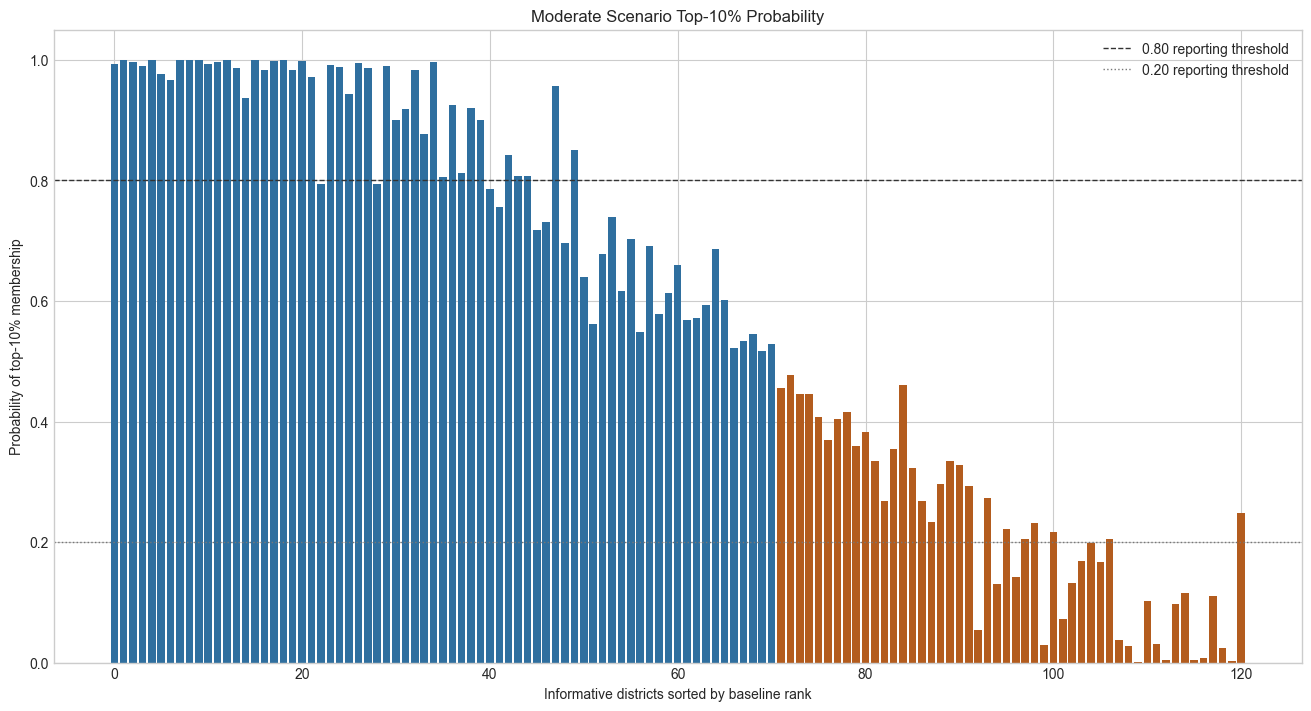

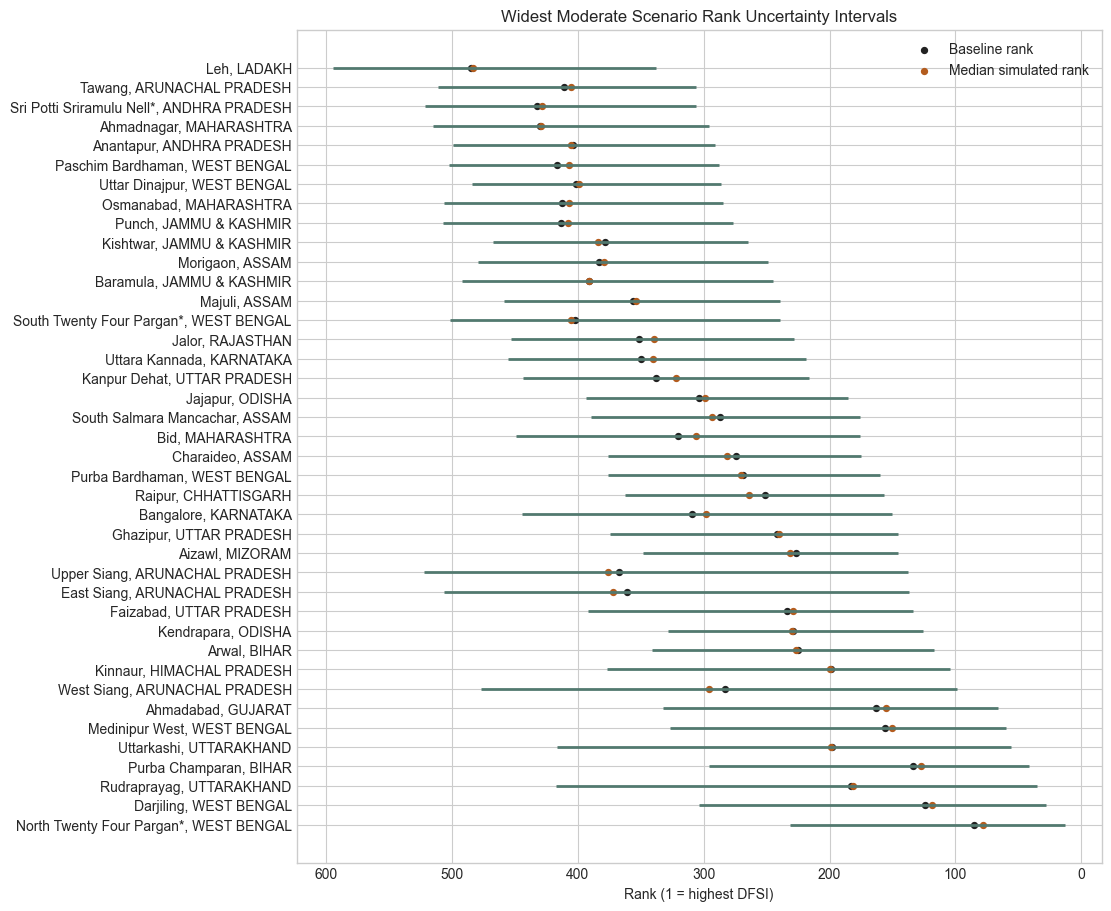

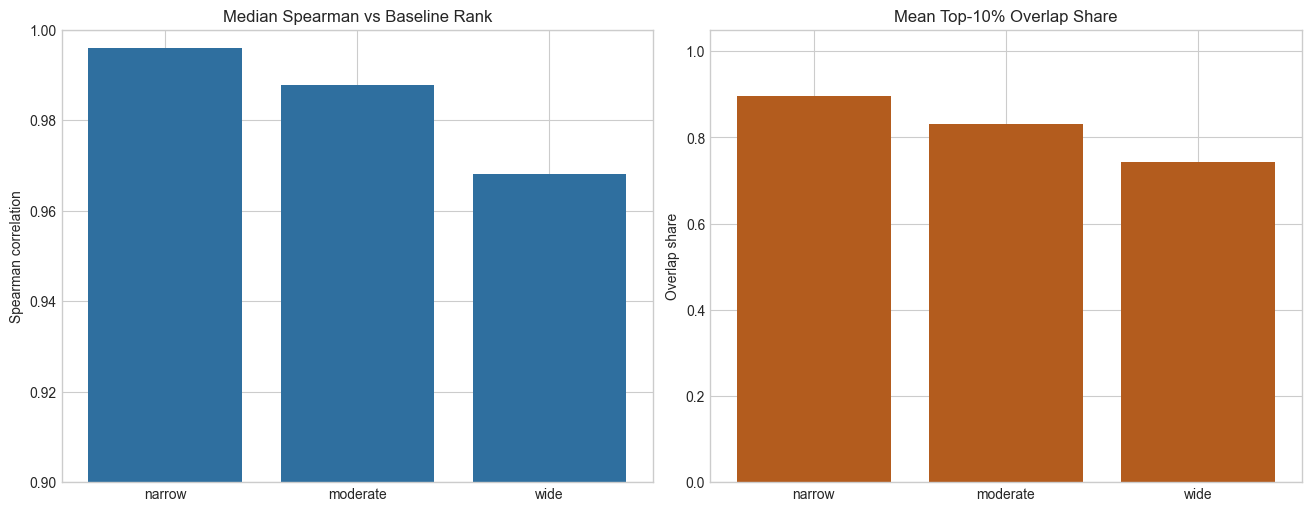

/var/folders/k9/rp4fy_356v95j5vs_8x2lp7c0000gn/T/ipykernel_19423/473778169.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=COMPONENTS, showfliers=False)
/var/folders/k9/rp4fy_356v95j5vs_8x2lp7c0000gn/T/ipykernel_19423/473778169.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=COMPONENTS, showfliers=False)
/var/folders/k9/rp4fy_356v95j5vs_8x2lp7c0000gn/T/ipykernel_19423/473778169.py:60: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=COMPONENTS, showfliers=False)


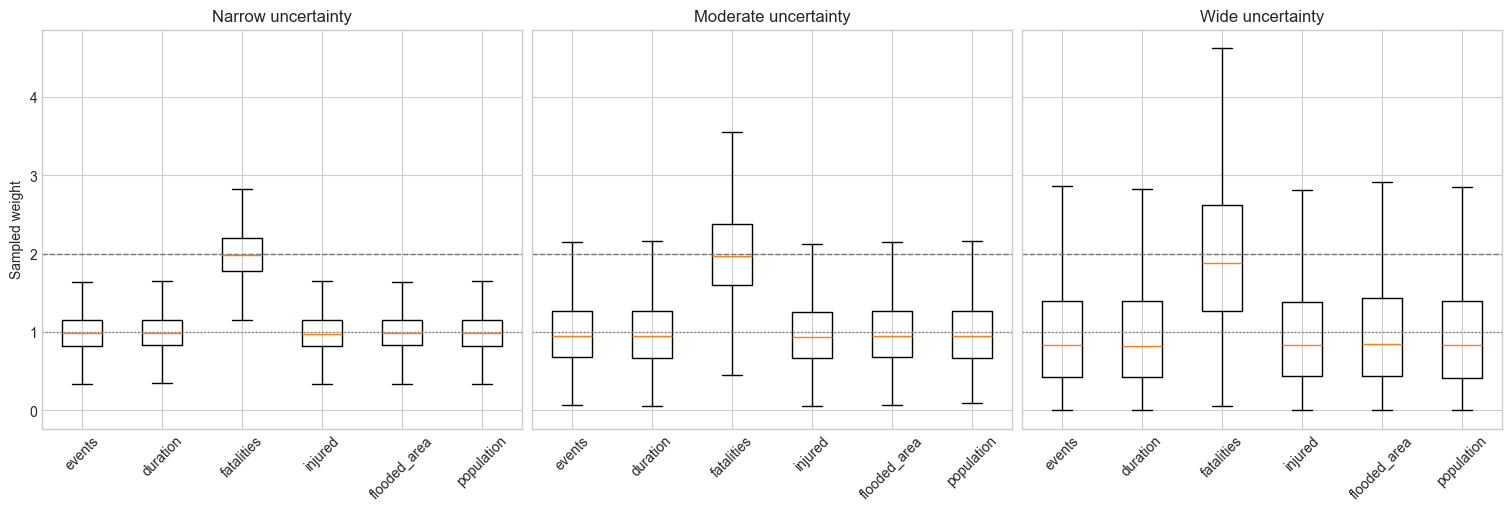

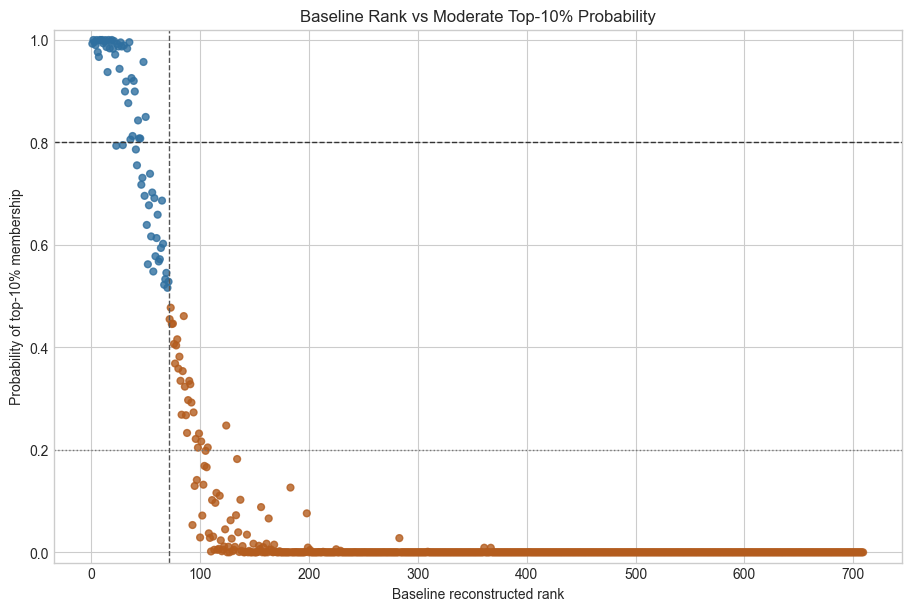

Saved figures:
- outputs/figures/dfsi_top10_probability_moderate.png (84,948 bytes)
- outputs/figures/dfsi_rank_uncertainty_intervals.png (316,900 bytes)
- outputs/figures/dfsi_monte_carlo_scenario_comparison.png (65,371 bytes)
- outputs/figures/dfsi_sampled_weight_distributions.png (75,844 bytes)
- outputs/figures/dfsi_baseline_rank_vs_top10_probability.png (135,643 bytes)


In [7]:
plt.style.use("seaborn-v0_8-whitegrid")

moderate_plot = moderate.copy()
moderate_plot["plot_group"] = np.where(moderate_plot["baseline_top10"], "Baseline top 10%", "Not baseline top 10%")
moderate_informative = moderate_plot.query("baseline_rank <= 120 or top10_probability > 0.20").sort_values("baseline_rank")
fig, ax = plt.subplots(figsize=(13, 7), constrained_layout=True)
colors = np.where(moderate_informative["baseline_top10"], "#2f6f9f", "#b35c1e")
ax.bar(np.arange(len(moderate_informative)), moderate_informative["top10_probability"], color=colors)
ax.axhline(0.80, color="#333333", linestyle="--", linewidth=1, label="0.80 reporting threshold")
ax.axhline(0.20, color="#777777", linestyle=":", linewidth=1, label="0.20 reporting threshold")
ax.set_title("Moderate Scenario Top-10% Probability")
ax.set_xlabel("Informative districts sorted by baseline rank")
ax.set_ylabel("Probability of top-10% membership")
ax.set_ylim(0, 1.05)
ax.legend()
top10_probability_path = FIGURE_DIR / "dfsi_top10_probability_moderate.png"
fig.savefig(top10_probability_path, dpi=200, bbox_inches="tight")
plt.show()

interval_plot = moderate.sort_values("rank_p05_to_p95_interval", ascending=False).head(40).sort_values("rank_p05")
y = np.arange(len(interval_plot))
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
ax.hlines(y, interval_plot["rank_p05"], interval_plot["rank_p95"], color="#52796f", linewidth=2)
ax.scatter(interval_plot["baseline_rank"], y, color="#222222", s=18, label="Baseline rank")
ax.scatter(interval_plot["median_simulated_rank"], y, color="#b35c1e", s=18, label="Median simulated rank")
ax.set_yticks(y)
ax.set_yticklabels(interval_plot["district_name"] + ", " + interval_plot["State_Name"].astype(str))
ax.invert_xaxis()
ax.set_title("Widest Moderate Scenario Rank Uncertainty Intervals")
ax.set_xlabel("Rank (1 = highest DFSI)")
ax.legend()
rank_interval_path = FIGURE_DIR / "dfsi_rank_uncertainty_intervals.png"
fig.savefig(rank_interval_path, dpi=200, bbox_inches="tight")
plt.show()

summary_plot = mc_scenario_summary.set_index("scenario").loc[["narrow", "moderate", "wide"]].reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
axes[0].bar(summary_plot["scenario"], summary_plot["median_spearman_correlation_with_baseline_rank"], color="#2f6f9f")
axes[0].set_ylim(0.9, 1.0)
axes[0].set_title("Median Spearman vs Baseline Rank")
axes[0].set_ylabel("Spearman correlation")
axes[1].bar(summary_plot["scenario"], summary_plot["mean_top10_overlap_with_baseline"] / TOP10_N, color="#b35c1e")
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Mean Top-10% Overlap Share")
axes[1].set_ylabel("Overlap share")
scenario_comparison_path = FIGURE_DIR / "dfsi_monte_carlo_scenario_comparison.png"
fig.savefig(scenario_comparison_path, dpi=200, bbox_inches="tight")
plt.show()

weights_long = mc_sampled_weights.melt(
    id_vars=["scenario", "simulation", "weight_sum"],
    value_vars=[f"weight_{component}" for component in COMPONENTS],
    var_name="component",
    value_name="weight",
)
weights_long["component"] = weights_long["component"].str.replace("weight_", "", regex=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, constrained_layout=True)
for ax, scenario in zip(axes, ["narrow", "moderate", "wide"]):
    data = [weights_long.query("scenario == @scenario and component == @component")["weight"] for component in COMPONENTS]
    ax.boxplot(data, labels=COMPONENTS, showfliers=False)
    ax.axhline(1.0, color="#777777", linestyle=":", linewidth=1)
    ax.axhline(2.0, color="#777777", linestyle="--", linewidth=1)
    ax.set_title(f"{scenario.title()} uncertainty")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Sampled weight")
weight_distribution_path = FIGURE_DIR / "dfsi_sampled_weight_distributions.png"
fig.savefig(weight_distribution_path, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
colors = np.where(moderate["baseline_top10"], "#2f6f9f", "#b35c1e")
ax.scatter(moderate["baseline_rank"], moderate["top10_probability"], c=colors, s=24, alpha=0.8)
ax.axhline(0.80, color="#333333", linestyle="--", linewidth=1)
ax.axhline(0.20, color="#777777", linestyle=":", linewidth=1)
ax.axvline(TOP10_N, color="#555555", linestyle="--", linewidth=1)
ax.set_title("Baseline Rank vs Moderate Top-10% Probability")
ax.set_xlabel("Baseline reconstructed rank")
ax.set_ylabel("Probability of top-10% membership")
ax.set_ylim(-0.02, 1.02)
baseline_vs_probability_path = FIGURE_DIR / "dfsi_baseline_rank_vs_top10_probability.png"
fig.savefig(baseline_vs_probability_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved figures:")
for path in [top10_probability_path, rank_interval_path, scenario_comparison_path, weight_distribution_path, baseline_vs_probability_path]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

## Final Answers

In [8]:
moderate = mc_district_uncertainty.query("scenario == 'moderate'").copy()
robust_count = int((moderate["priority_stability_category"] == "Robust high priority").sum())
sensitive_count = int((moderate["priority_stability_category"] == "Weight-sensitive priority").sum())
baseline_top10_below_80_count = int((moderate["baseline_top10"] & moderate["top10_probability"].lt(0.80)).sum())
widest_rank = moderate.sort_values("rank_p05_to_p95_interval", ascending=False).head(10)
moderate_summary = mc_scenario_summary.query("scenario == 'moderate'").iloc[0]

print("Concise Monte Carlo interpretation")
print(f"A. Robust high-priority districts: {robust_count}")
print(f"B. Weight-sensitive priority districts: {sensitive_count}")
print(f"C. Baseline top-10% districts below 80% retention probability: {baseline_top10_below_80_count}")
print("D. Widest rank uncertainty districts:")
print(", ".join(f"{row.district_name} ({row.State_Name}, interval {row.rank_p05_to_p95_interval:.0f})" for row in widest_rank.itertuples(index=False)))
print("E. Does moderate weight uncertainty materially change flood-priority decisions even when national rank correlations remain high?")
print(
    f"Yes. Median Spearman remains {moderate_summary.median_spearman_correlation_with_baseline_rank:.4f}, "
    f"but {baseline_top10_below_80_count} baseline top-10% districts fall below the 0.80 reporting threshold and "
    f"{sensitive_count} districts are weight-sensitive priorities."
)
print("F. Main paper scenario recommendation:")
print("Use the moderate uncertainty scenario as the main result: it is centred on the published weights, less brittle than the narrow scenario, and avoids making the wide scenario the default stress test.")

answer_summary = pd.DataFrame([
    {"question": "A", "answer": robust_count},
    {"question": "B", "answer": sensitive_count},
    {"question": "C", "answer": baseline_top10_below_80_count},
    {"question": "D", "answer": "; ".join(f"{row.district_name} ({row.State_Name}, interval {row.rank_p05_to_p95_interval:.0f})" for row in widest_rank.itertuples(index=False))},
    {"question": "E", "answer": f"Yes; median Spearman {moderate_summary.median_spearman_correlation_with_baseline_rank:.4f} coexists with top-priority membership instability."},
    {"question": "F", "answer": "Moderate uncertainty scenario"},
])
display(answer_summary)

Concise Monte Carlo interpretation
A. Robust high-priority districts: 43
B. Weight-sensitive priority districts: 56
C. Baseline top-10% districts below 80% retention probability: 28
D. Widest rank uncertainty districts:
Upper Siang (ARUNACHAL PRADESH, interval 384), Rudraprayag (UTTARAKHAND, interval 382), West Siang (ARUNACHAL PRADESH, interval 378), East Siang (ARUNACHAL PRADESH, interval 369), Uttarkashi (UTTARAKHAND, interval 360), Bangalore (KARNATAKA, interval 294), Darjiling (WEST BENGAL, interval 276), Bid (MAHARASHTRA, interval 273), Kinnaur (HIMACHAL PRADESH, interval 273), Medinipur West (WEST BENGAL, interval 267)
E. Does moderate weight uncertainty materially change flood-priority decisions even when national rank correlations remain high?
Yes. Median Spearman remains 0.9878, but 28 baseline top-10% districts fall below the 0.80 reporting threshold and 56 districts are weight-sensitive priorities.
F. Main paper scenario recommendation:
Use the moderate uncertainty scenario

,question,answer
0,A,43
1,B,56
2,C,28
3,D,"Upper Siang (ARUNACHAL PRADESH, interval 384); Rudraprayag (UTTARAKHAND, interval 382); West Siang (ARUNACHAL PRADESH, interval 378); East Siang (ARUNACHAL PRADESH, interval 36..."
4,E,Yes; median Spearman 0.9878 coexists with top-priority membership instability.
5,F,Moderate uncertainty scenario


## Output Manifest

In [9]:
print("Saved outputs:")
for path in [
    TABLE_DIR / "dfsi_monte_carlo_district_uncertainty.csv",
    TABLE_DIR / "dfsi_monte_carlo_scenario_summary.csv",
    TABLE_DIR / "dfsi_monte_carlo_weight_summary.csv",
    TABLE_DIR / "dfsi_monte_carlo_sampled_weights.csv",
    TABLE_DIR / "dfsi_monte_carlo_sensitive_districts.csv",
    TABLE_DIR / "dfsi_monte_carlo_robust_hotspots.csv",
    TABLE_DIR / "dfsi_monte_carlo_top10_transitions.csv",
    FIGURE_DIR / "dfsi_top10_probability_moderate.png",
    FIGURE_DIR / "dfsi_rank_uncertainty_intervals.png",
    FIGURE_DIR / "dfsi_monte_carlo_scenario_comparison.png",
    FIGURE_DIR / "dfsi_sampled_weight_distributions.png",
    FIGURE_DIR / "dfsi_baseline_rank_vs_top10_probability.png",
]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

Saved outputs:
- outputs/tables/dfsi_monte_carlo_district_uncertainty.csv (542,475 bytes)
- outputs/tables/dfsi_monte_carlo_scenario_summary.csv (865 bytes)
- outputs/tables/dfsi_monte_carlo_weight_summary.csv (3,520 bytes)
- outputs/tables/dfsi_monte_carlo_sampled_weights.csv (4,090,613 bytes)
- outputs/tables/dfsi_monte_carlo_sensitive_districts.csv (30,118 bytes)
- outputs/tables/dfsi_monte_carlo_robust_hotspots.csv (7,372 bytes)
- outputs/tables/dfsi_monte_carlo_top10_transitions.csv (21,185 bytes)
- outputs/figures/dfsi_top10_probability_moderate.png (84,948 bytes)
- outputs/figures/dfsi_rank_uncertainty_intervals.png (316,900 bytes)
- outputs/figures/dfsi_monte_carlo_scenario_comparison.png (65,371 bytes)
- outputs/figures/dfsi_sampled_weight_distributions.png (75,844 bytes)
- outputs/figures/dfsi_baseline_rank_vs_top10_probability.png (135,643 bytes)
